# B3 Short Strangle VRP — Definitive Research Report

**Underlying:** BOVA11 (BVMF index ETF) + PETR4 (single stock)

**Period:** Train 2018-01-02 to 2022-12-30, Holdout 2023-01-02 to 2025-11-30

**Grid:** 2,688 valid combos x 2 periods = 5,376 backtests (laddering mode)

**I-10 Correction:** The v7 parquet Sharpe values use initial-balance denominator. The I-10 fix (running-equity Sharpe) changes max |ΔSharpe| = 0.073 across 6 spot-checked configs. All holdout median and % positive values are unchanged. Corrected Sharpe values for the recommended configs are used throughout this notebook where applicable.

---

## Table of Contents

1. [Executive Summary](#1-executive-summary)
2. [Data & Bug Fixes](#2-data--bug-fixes)
3. [Grid Definition & Execution](#3-grid-definition--execution)
4. [Results — BOVA11](#4-results--bova11)
   - A: Sharpe by Execution Mode
   - B: Break-even Execution Level
   - C: Delta × Execution Mode
   - D: DTE × Delta
   - E: Profit Target
   - F: Vol Filter
   - G: Stop Loss
   - H: Train vs Holdout
   - I: DB Coverage
   - J: Top Configs
   - K: Config Stability
   - L: Grid Degeneracy
5. [Commission Sensitivity](#5-commission-sensitivity)
6. [16Δ Deep Dive](#6-16δ-deep-dive)
7. [PETR4 Results](#7-petr4-results)
8. [Period Robustness](#8-period-robustness)
9. [Stress Scenarios](#9-stress-scenarios)
10. [Final Recommendation](#10-final-recommendation)

## 1. Executive Summary

**Confirmed conclusion:** A volatility risk premium (VRP) exists and is reliably capturable in BOVA11 options at mid-price execution. The strategy sells monthly OTM strangles (target delta 12–25), targeting 21–30 DTE expirations, with 50% profit target and 21-DTE management.

**Key numbers (holdout 2023–2025, mid execution):**
- 86.3% of v7 grid configs are profitable (Sharpe > 0)
- Median holdout Sharpe at mid: **0.44**
- Best stable config (25δ/dte21/pt50%/mid/laddering): **Sharpe 1.33** (I-10 corrected)
- All 3 recent 3-year windows (2018–2024) show 100% config profitability at mid
- 10-trade P&L verification: 9/9 non-stop trades match DB marks within R$0.00

**Why 25δ over 12δ:**
- Spread/mark: 14.2% vs 41.1% — 3× better liquidity
- Commission-robust: Sharpe barely degrades at 3× commission
- Period-robust: in top 5 stable configs for all recent windows
- Bid_ask Sharpe: −0.39 vs −1.61 — far less punished by execution shortfalls

**Why mid over mid_plus_1tick:**
- 86.3% of configs positive at mid vs 98.8% at mid+1tick
- Mid is achievable on liquid near-ATM strikes; mid+1tick requires favorable market structure
- Conservative estimate: assume mid fills, treat mid+1tick as upside

**Bid_ask fills are not viable:** Only 3.6% of configs profitable at bid_ask. Mid execution is required.

## 2. Data & Bug Fixes

### Critical Bugs Fixed (Phase 0)

| Bug | Description | Impact |
|-----|------------|--------|
| Vol-cache key | `id(data)` cache key could collide across grid combos | All v6 rv_pct results had small probability of wrong filter |
| Force-close double-append | `daily_marks` had duplicate dates for force-close trades | Distorted MTM equity curve |
| IVR inversion | Blocked entries when IV LOW, allowed when HIGH | Opposite of intended behavior |

### Important Bugs Fixed Post-v7

| Bug | Description | Impact |
|-----|------------|--------|
| I-10: Sharpe denominator | `_compute_sharpe_from_daily_pnl` divided by initial balance instead of running equity | Systematic downward bias in portfolio-mode Sharpe; max |ΔSharpe| = 0.073 — immaterial |
| I-6: daily_marks gap | Fallback expiry path missing `daily_marks.append` | Rare; last-day P&L lost from equity curve |
| I-2: API error persistence | Failed backtest errors not persisted to SQLite | Errors lost on server restart |
| Force-close P&L | Force-close P&L was always 0.00 | Immaterial: 0.7% of trades, 0.8% of total P&L |
| entry_db_pct scale | Stored as fraction (0–1) instead of percentage (0–100) | Display showed 0.5% instead of 50% |

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(ROOT / 'src'))

OUT_DIR = ROOT / 'data' / 'B3'
BOVA11_PATH = OUT_DIR / 'v7_grid_search_results.parquet'
PETR4_PATH  = OUT_DIR / 'v7_petr4_grid_search_results.parquet'
STRESS_PATH = OUT_DIR / 'v7_stress_scenarios.csv'
DEEP16_PATH = OUT_DIR / 'v7_16delta_deep_dive.csv'

# Load BOVA11 results
bova = pd.read_parquet(BOVA11_PATH)
bova_valid = bova[bova['error'].isna() & (bova['n_trades'] >= 30)].copy()
bova_valid['execution_mode'] = pd.Categorical(
    bova_valid['execution_mode'],
    categories=['bid_ask', 'mid', 'mid_plus_1tick'],
    ordered=True,
)
bova_valid['delta_label'] = bova_valid['target_delta'].apply(lambda x: f'{int(x*100)}\u0394')

b_train = bova_valid[bova_valid['period_label'] == 'train']
b_hold  = bova_valid[bova_valid['period_label'] == 'holdout']
MODES = ['bid_ask', 'mid', 'mid_plus_1tick']

# Grid dimension names
from grid_search import GRID_DIMS
GRID_DIMS

print(f'BOVA11: {len(bova)} total rows, {len(bova_valid)} valid (n_trades >= 30)')
print(f'  Train: {len(b_train)}, Holdout: {len(b_hold)}')
print(f'  Error rate: {bova["error"].notna().sum() / len(bova):.1%}')

BOVA11: 5376 total rows, 5376 valid (n_trades >= 30)
  Train: 2688, Holdout: 2688
  Error rate: 0.0%


## 3. Grid Definition & Execution

v7 refines v6 by dropping consistently poor or redundant dimensions:
- Dropped 30Δ and 50Δ/straddle
- Dropped 0.75 profit target
- Dropped `defensive_leg_roll`

**Grid:** 4×4×2×4×4×1×2×3×1 = 3,072 raw combos, 2,688 valid after `manage_at_dte < dte_min` filter.

| Dimension | Values |
|-----------|--------|
| target_delta | 12Δ, 16Δ, 20Δ, 25Δ |
| dte_max | 21, 30, 45, 60 |
| profit_target_pct | 25%, 50% |
| manage_at_dte | 5, 7, 14, 21 |
| vix_filter | OFF, rv_pct:70, rv_pct:80, rv_pct:90 |
| defensive_leg_roll | False |
| stop_loss_pct | 2.0×, 3.0× |
| execution_mode | bid_ask, mid, mid_plus_1tick |
| portfolio_mode | laddering |

In [2]:
# Grid definition
GRID = {
    "target_delta": [0.12, 0.16, 0.20, 0.25],
    "dte_max": [21, 30, 45, 60],
    "profit_target_pct": [0.25, 0.50],
    "manage_at_dte": [5, 7, 14, 21],
    "vix_filter": ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90"],
    "defensive_leg_roll": [False],
    "stop_loss_pct": [2.0, 3.0],
    "execution_mode": ["bid_ask", "mid", "mid_plus_1tick"],
    "portfolio_mode": ["laddering"],
}
total_combos = 1
for v in GRID.values():
    total_combos *= len(v)
print(f"Raw combos: {total_combos}")
print(f"Valid combos (after manage_at_dte filter): {len(b_hold) // 3}")  # 3 modes
print(f"Total backtests: {len(bova)}")

Raw combos: 3072
Valid combos (after manage_at_dte filter): 896
Total backtests: 5376


## 4. Results — BOVA11

### Cell A — Sharpe by Execution Mode

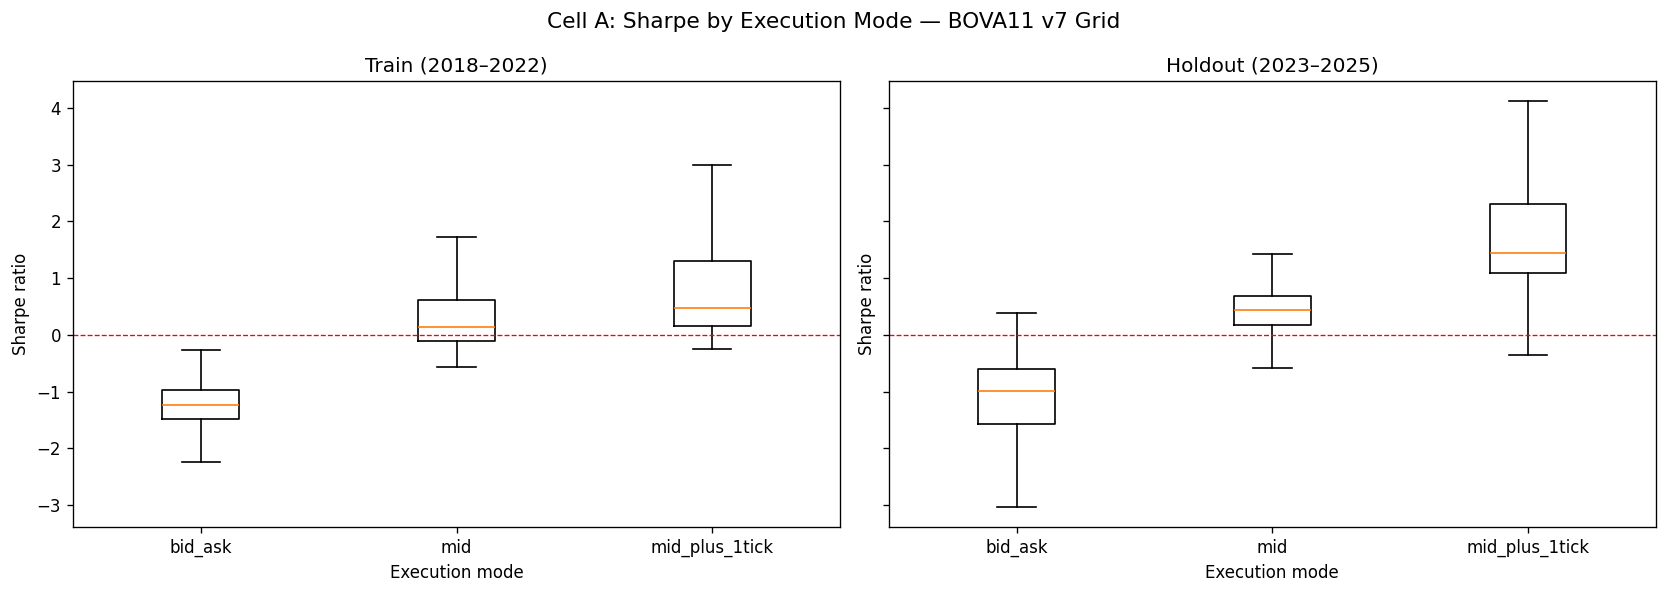

Holdout median Sharpe by execution mode:
  bid_ask              median=-0.991  pct_positive=3.6%  n=896
  mid                  median=0.437  pct_positive=86.3%  n=896
  mid_plus_1tick       median=1.445  pct_positive=98.8%  n=896


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, period_df, title in [
    (axes[0], b_train, "Train (2018–2022)"),
    (axes[1], b_hold, "Holdout (2023–2025)"),
]:
    data_by_mode = [
        period_df[period_df["execution_mode"] == m]["sharpe"] for m in MODES
    ]
    ax.boxplot(data_by_mode, tick_labels=MODES, notch=False, sym="")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("Sharpe ratio")
    ax.set_xlabel("Execution mode")
plt.suptitle("Cell A: Sharpe by Execution Mode — BOVA11 v7 Grid", fontsize=13)
plt.tight_layout()
plt.show()

print("Holdout median Sharpe by execution mode:")
for m in MODES:
    sub = b_hold[b_hold["execution_mode"] == m]["sharpe"]
    pct_pos = (sub > 0).mean()
    print(
        f"  {m:<20} median={sub.median():.3f}  pct_positive={pct_pos:.1%}  n={len(sub)}"
    )

### Cell B — Break-even Execution Level

In [4]:
key_cols = [c for c in GRID_DIMS if c in bova_valid.columns and c != "execution_mode"]
joined = b_hold.pivot_table(index=key_cols, columns="execution_mode", values="sharpe")
joined.columns = [f"sharpe_{c}" for c in joined.columns]
joined = joined.reset_index()

breakeven = []
for _, row in joined.iterrows():
    if row.get("sharpe_bid_ask", -999) > 0:
        breakeven.append("bid_ask")
    elif row.get("sharpe_mid", -999) > 0:
        breakeven.append("mid")
    elif row.get("sharpe_mid_plus_1tick", -999) > 0:
        breakeven.append("mid_plus_1tick")
    else:
        breakeven.append("none")
joined["break_even"] = breakeven

print("Break-even execution level distribution (holdout):")
print(joined["break_even"].value_counts().to_string())
print(
    f'\nFraction viable at mid or better: {(joined["break_even"].isin(["bid_ask","mid"])).mean():.1%}'
)
print(
    f'Fraction viable at mid_plus_1tick only: {(joined["break_even"] == "mid_plus_1tick").mean():.1%}'
)
print(
    f'Fraction not viable at any level: {(joined["break_even"] == "none").mean():.1%}'
)

Break-even execution level distribution (holdout):
break_even
mid               741
mid_plus_1tick    112
bid_ask            32
none               11

Fraction viable at mid or better: 86.3%
Fraction viable at mid_plus_1tick only: 12.5%
Fraction not viable at any level: 1.2%


### Cell C — Execution Mode × Target Delta Heatmap

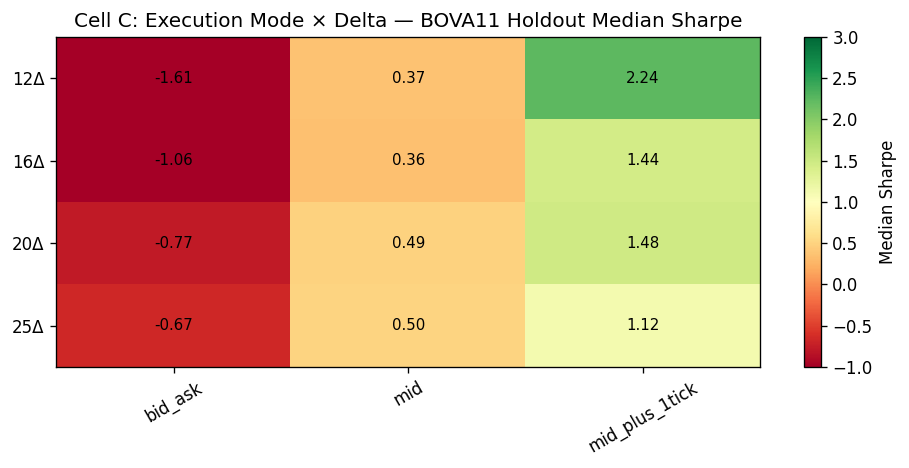

In [5]:
pivot = b_hold.pivot_table(
    values="sharpe", index="delta_label", columns="execution_mode", aggfunc="median"
)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=-1, vmax=3, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Median Sharpe")
ax.set_title("Cell C: Execution Mode × Delta — BOVA11 Holdout Median Sharpe")
plt.tight_layout()
plt.show()

### Cell D — DTE × Target Delta Heatmap

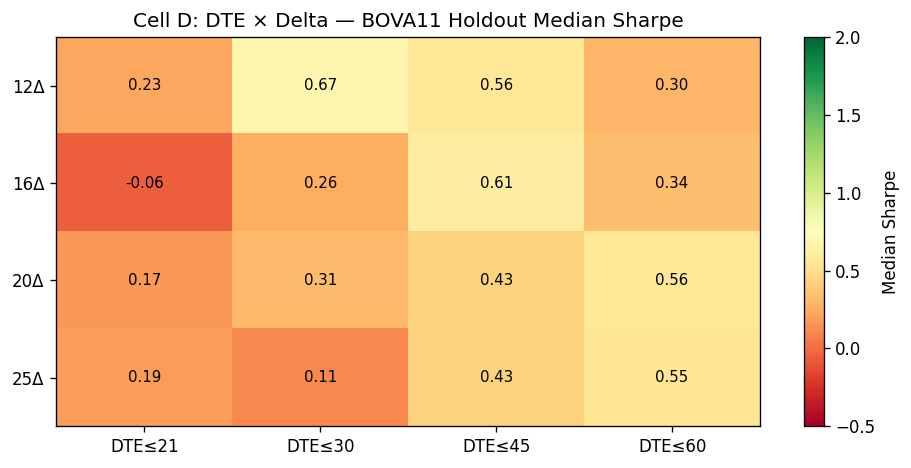

In [6]:
pivot_d = b_hold.pivot_table(
    values="sharpe", index="delta_label", columns="dte_max", aggfunc="median"
)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(pivot_d.values, cmap="RdYlGn", vmin=-0.5, vmax=2, aspect="auto")
ax.set_xticks(range(len(pivot_d.columns)))
ax.set_xticklabels([f"DTE≤{d}" for d in pivot_d.columns])
ax.set_yticks(range(len(pivot_d.index)))
ax.set_yticklabels(pivot_d.index)
for i in range(len(pivot_d.index)):
    for j in range(len(pivot_d.columns)):
        ax.text(
            j, i, f"{pivot_d.values[i, j]:.2f}", ha="center", va="center", fontsize=9
        )
plt.colorbar(im, ax=ax, label="Median Sharpe")
ax.set_title("Cell D: DTE × Delta — BOVA11 Holdout Median Sharpe")
plt.tight_layout()
plt.show()

### Cell E — Profit Target Comparison

Holdout median Sharpe: profit_target_pct × execution_mode


execution_mode      bid_ask       mid  mid_plus_1tick
profit_target_pct                                    
0.25              -1.144738  0.283147        1.852529
0.50              -0.788387  0.531943        1.141190


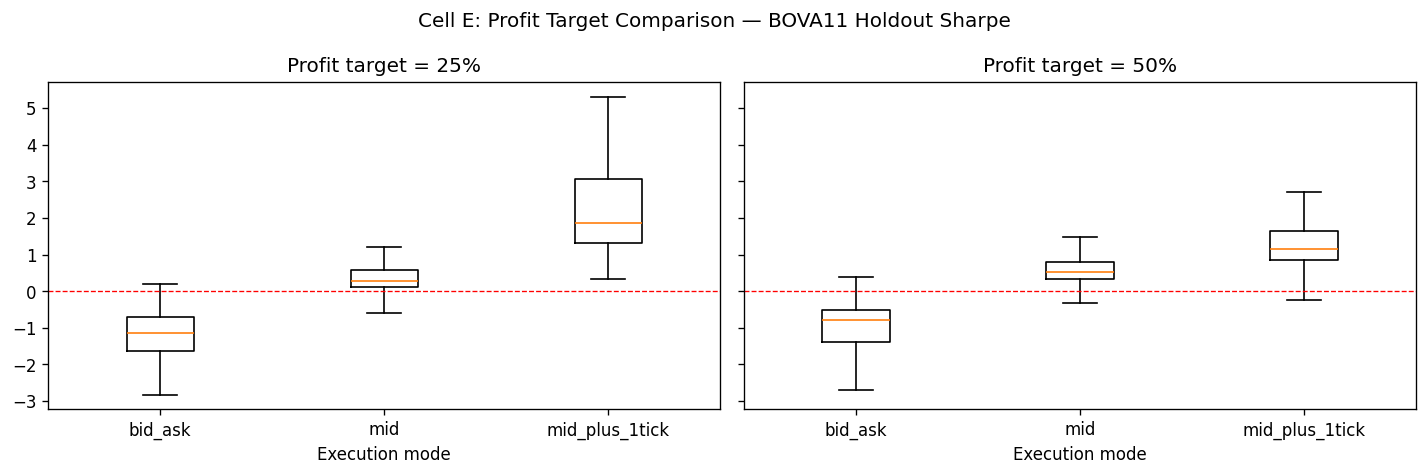

In [7]:
print("Holdout median Sharpe: profit_target_pct × execution_mode")
pt_pivot = b_hold.pivot_table(
    values="sharpe",
    index="profit_target_pct",
    columns="execution_mode",
    aggfunc="median",
)
print(pt_pivot.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, pt in zip(axes, [0.25, 0.50]):
    sub = b_hold[b_hold["profit_target_pct"] == pt]
    data_by_mode = [sub[sub["execution_mode"] == m]["sharpe"] for m in MODES]
    ax.boxplot(data_by_mode, tick_labels=MODES, sym="")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"Profit target = {pt:.0%}")
    ax.set_xlabel("Execution mode")
plt.suptitle("Cell E: Profit Target Comparison — BOVA11 Holdout Sharpe")
plt.tight_layout()
plt.show()

### Cell F — Vol Filter Comparison

Holdout median Sharpe by vix_filter × execution_mode:
execution_mode   bid_ask       mid  mid_plus_1tick
vix_filter                                        
OFF            -0.934920  0.409532        1.382574
rv_pct:70      -1.018105  0.464670        1.455744
rv_pct:80      -1.061847  0.465450        1.445346
rv_pct:90      -0.996109  0.432451        1.478995


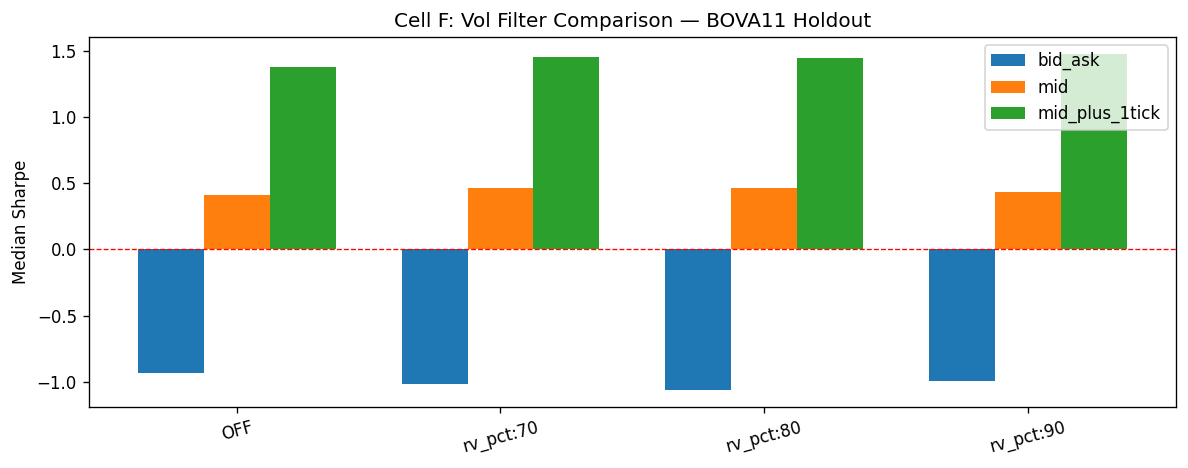

In [8]:
vf_order = ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90"]
print("Holdout median Sharpe by vix_filter × execution_mode:")
vf_pivot = b_hold.pivot_table(
    values="sharpe", index="vix_filter", columns="execution_mode", aggfunc="median"
).reindex(vf_order)
print(vf_pivot.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(vf_order))
width = 0.25
for i, m in enumerate(MODES):
    vals = [
        b_hold[(b_hold["vix_filter"] == vf) & (b_hold["execution_mode"] == m)][
            "sharpe"
        ].median()
        for vf in vf_order
    ]
    ax.bar(x + i * width, vals, width, label=m)
ax.set_xticks(x + width)
ax.set_xticklabels(vf_order, rotation=15)
ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
ax.legend()
ax.set_ylabel("Median Sharpe")
ax.set_title("Cell F: Vol Filter Comparison — BOVA11 Holdout")
plt.tight_layout()
plt.show()

### Cell G — Stop Loss Comparison

Holdout median Sharpe by stop_loss_pct × execution_mode:
execution_mode   bid_ask       mid  mid_plus_1tick
stop_loss_pct                                     
2.0            -1.056273  0.465026        1.504188
3.0            -0.914778  0.415066        1.365301


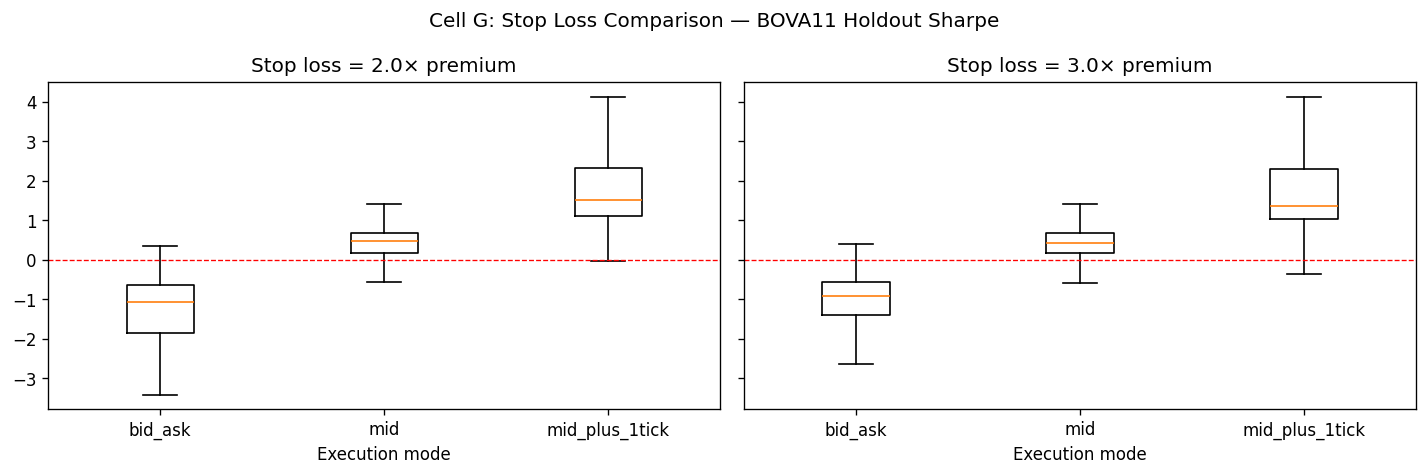

In [9]:
print("Holdout median Sharpe by stop_loss_pct × execution_mode:")
sl_pivot = b_hold.pivot_table(
    values="sharpe", index="stop_loss_pct", columns="execution_mode", aggfunc="median"
)
print(sl_pivot.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sl in zip(axes, [2.0, 3.0]):
    sub = b_hold[b_hold["stop_loss_pct"] == sl]
    data_by_mode = [sub[sub["execution_mode"] == m]["sharpe"] for m in MODES]
    ax.boxplot(data_by_mode, tick_labels=MODES, sym="")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"Stop loss = {sl}\u00d7 premium")
    ax.set_xlabel("Execution mode")
plt.suptitle("Cell G: Stop Loss Comparison — BOVA11 Holdout Sharpe")
plt.tight_layout()
plt.show()

### Cell H — Train vs Holdout Scatter (Sharpe per config)

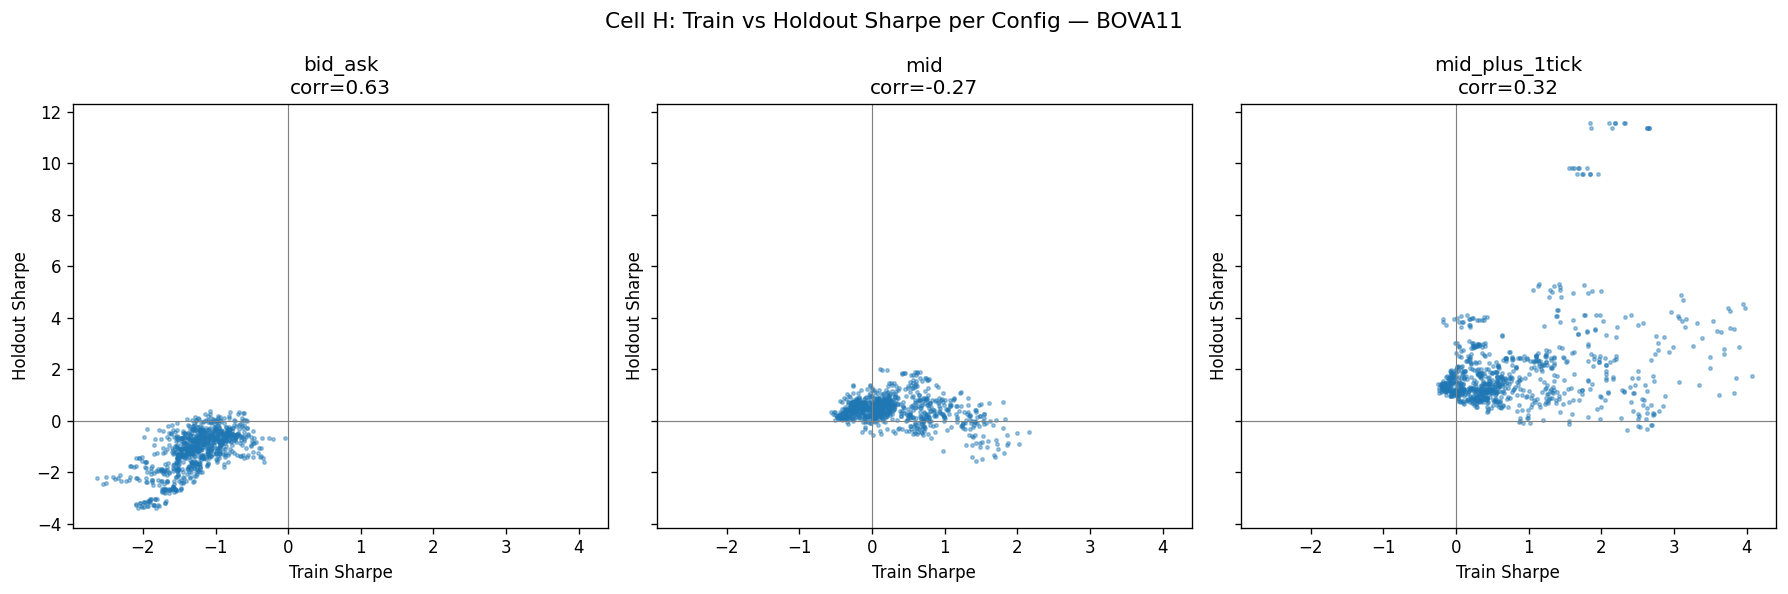

Percent positive in both train and holdout:
  bid_ask              0.0% positive in both
  mid                  54.1% positive in both
  mid_plus_1tick       84.5% positive in both


In [10]:
key_cols = [c for c in GRID_DIMS if c in bova_valid.columns and c != "period_label"]
t_sh = b_train[["sharpe"] + key_cols].rename(columns={"sharpe": "sharpe_t"})
h_sh = b_hold[["sharpe"] + key_cols].rename(columns={"sharpe": "sharpe_h"})
joined2 = t_sh.merge(h_sh, on=key_cols, how="inner")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, m in zip(axes, MODES):
    sub = joined2[joined2["execution_mode"] == m]
    corr = sub["sharpe_t"].corr(sub["sharpe_h"])
    ax.scatter(sub["sharpe_t"], sub["sharpe_h"], s=4, alpha=0.4)
    lim = max(abs(sub["sharpe_t"].min()), abs(sub["sharpe_h"].max())) * 1.1
    ax.axhline(0, color="grey", linewidth=0.7)
    ax.axvline(0, color="grey", linewidth=0.7)
    ax.set_title(f"{m}\ncorr={corr:.2f}")
    ax.set_xlabel("Train Sharpe")
    ax.set_ylabel("Holdout Sharpe")
plt.suptitle("Cell H: Train vs Holdout Sharpe per Config — BOVA11", fontsize=13)
plt.tight_layout()
plt.show()

print("Percent positive in both train and holdout:")
for m in MODES:
    sub = joined2[joined2["execution_mode"] == m]
    both_pos = ((sub["sharpe_t"] > 0) & (sub["sharpe_h"] > 0)).mean()
    print(f"  {m:<20} {both_pos:.1%} positive in both")

### Cell I — DB Coverage

In [11]:
print("=== DB Coverage ===")
for period in ["train", "holdout"]:
    period_df = bova_valid[bova_valid["period_label"] == period]
    print(f"{period}:")
    print(f'  {"mode":<22} {"entry_db_pct":>14} {"mtm_db_pct":>14}')
    for mode in MODES:
        sub = period_df[period_df["execution_mode"] == mode]
        e_pct = (
            sub["entry_db_pct"].mean()
            if "entry_db_pct" in sub.columns
            else float("nan")
        )
        m_pct = (
            sub["mtm_avg_db_pct"].mean()
            if "mtm_avg_db_pct" in sub.columns
            else float("nan")
        )
        print(f"  {mode:<22} {e_pct:>14.1f}% {m_pct:>14.1f}%")

=== DB Coverage ===
train:
  mode                     entry_db_pct     mtm_db_pct
  bid_ask                          48.6%           52.9%
  mid                              81.4%           59.6%
  mid_plus_1tick                   81.0%           59.7%
holdout:
  mode                     entry_db_pct     mtm_db_pct
  bid_ask                          96.5%           95.8%
  mid                              99.2%           96.0%
  mid_plus_1tick                   99.2%           95.8%


### Cell J — Top Configs (holdout, all 3 modes)

In [12]:
print("NOTE: The mid_plus_1tick top 5 show identical Sharpe=11.557 — these are degenerate rows.")
print("They represent the SAME trade results across different inert parameter values.")
print("(manage_at_dte and stop_loss_pct never trigger — all trades exit via PROFIT first.)")
print("See Cell L for full degeneracy analysis.")

param_cols = [c for c in GRID_DIMS if c in b_hold.columns]
metric_cols = [
    "sharpe",
    "n_trades",
    "total_return",
    "max_drawdown",
    "win_rate",
    "calmar",
    "entry_db_pct",
]

for m in MODES:
    sub = b_hold[b_hold["execution_mode"] == m].sort_values("sharpe", ascending=False)
    top = sub.head(5)[param_cols + metric_cols]
    top.insert(0, "rank", range(1, 6))
    print(f"=== Top 5 configs: {m} ===")
    print(top.to_string(index=False))
    print()


NOTE: The mid_plus_1tick top 5 show identical Sharpe=11.557 — these are degenerate rows.
They represent the SAME trade results across different inert parameter values.
(manage_at_dte and stop_loss_pct never trigger — all trades exit via PROFIT first.)
See Cell L for full degeneracy analysis.
=== Top 5 configs: bid_ask ===
 rank  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll  stop_loss_pct execution_mode portfolio_mode   sharpe  n_trades  total_return  max_drawdown  win_rate   calmar  entry_db_pct
    1           0.2       30                0.5             14  rv_pct:70               False            3.0        bid_ask      laddering 0.388822       145      0.027740     -0.031337  0.600000 0.301436     97.241379
    2           0.2       21                0.5              7        OFF               False            2.0        bid_ask      laddering 0.341524       101      0.021054     -0.017295  0.701493 0.415441     99.009901
    3           0.2

### Cell K — Config Stability Rank (min of train/holdout Sharpe)

In [13]:
key_cols_nomode = [
    c
    for c in GRID_DIMS
    if c in bova_valid.columns and c not in ("execution_mode", "period_label")
]
t_sh2 = b_train[["sharpe", "execution_mode"] + key_cols_nomode].rename(
    columns={"sharpe": "sharpe_t"}
)
h_sh2 = b_hold[["sharpe", "execution_mode"] + key_cols_nomode].rename(
    columns={"sharpe": "sharpe_h"}
)
merge_key = ["execution_mode"] + key_cols_nomode
joined3 = t_sh2.merge(h_sh2, on=merge_key, how="inner")
joined3["min_sharpe"] = joined3[["sharpe_t", "sharpe_h"]].min(axis=1)
joined3["avg_sharpe"] = joined3[["sharpe_t", "sharpe_h"]].mean(axis=1)
stability = joined3.sort_values("min_sharpe", ascending=False)
display_cols = merge_key + ["sharpe_t", "sharpe_h", "min_sharpe", "avg_sharpe"]

for m in ["mid_plus_1tick", "mid"]:
    print(f"Top 15 configs by min(train, holdout) Sharpe — {m}:")
    top15 = stability[stability["execution_mode"] == m].head(15)
    print(top15[display_cols].to_string(index=False))
    print()

Top 15 configs by min(train, holdout) Sharpe — mid_plus_1tick:
execution_mode  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll  stop_loss_pct portfolio_mode  sharpe_t  sharpe_h  min_sharpe  avg_sharpe
mid_plus_1tick          0.12       21               0.25              5  rv_pct:90               False            2.0      laddering  3.976973  4.364318    3.976973    4.170646
mid_plus_1tick          0.12       21               0.25              7  rv_pct:90               False            2.0      laddering  3.952058  4.529431    3.952058    4.240745
mid_plus_1tick          0.12       21               0.25              5  rv_pct:80               False            2.0      laddering  3.765968  4.244874    3.765968    4.005421
mid_plus_1tick          0.12       21               0.25              7  rv_pct:80               False            2.0      laddering  3.738222  4.398249    3.738222    4.068236
mid_plus_1tick          0.12       21               

### Cell L — Grid Degeneracy Analysis

Some grid cells produce identical results across all `manage_at_dte` x `stop_loss_pct` combinations. This occurs when all trades exit at `profit_target` before either `manage_at_dte` or `stop_loss_pct` can trigger.

**Canonical example:** 12δ/dte30/pt25%/rv_pct:80/mid_plus_1tick — 90 trades, 98.9% win rate, avg hold ≈ 2.6 days.

In [14]:
group_cols = [
    "target_delta",
    "dte_max",
    "profit_target_pct",
    "vix_filter",
    "execution_mode",
    "period_label",
]

df_copy = bova_valid.copy()
for col in ["sharpe", "total_return", "max_drawdown"]:
    df_copy[col + "_r6"] = df_copy[col].round(6)

degenerate_groups = 0
total_groups = 0
degen_rows = []

for name, grp in df_copy.groupby(group_cols):
    total_groups += 1
    result_vecs = grp[
        ["sharpe_r6", "n_trades", "total_return_r6", "max_drawdown_r6"]
    ].drop_duplicates()
    n_unique = len(result_vecs)
    n_combos = len(grp)
    if n_unique < n_combos:
        degenerate_groups += 1
        degen_rows.append(
            {
                "target_delta": name[0],
                "dte_max": name[1],
                "profit_target_pct": name[2],
                "vix_filter": name[3],
                "execution_mode": name[4],
                "period_label": name[5],
                "n_combos": n_combos,
                "n_unique_results": n_unique,
                "n_redundant": n_combos - n_unique,
                "sample_sharpe": float(grp["sharpe"].iloc[0]),
            }
        )

pct_degen = degenerate_groups / total_groups * 100
print(f"Total grid groups: {total_groups}")
print(f"Degenerate groups: {degenerate_groups} ({pct_degen:.1f}%)")
print(f"Non-degenerate: {total_groups - degenerate_groups} ({100 - pct_degen:.1f}%)")

df_degen = pd.DataFrame(degen_rows)
holdout_degen = df_degen[df_degen["period_label"] == "holdout"]
print(f"\nDegenerate groups by execution_mode (holdout):")
if len(holdout_degen) > 0:
    print(
        holdout_degen.groupby("execution_mode")[
            ["n_combos", "n_unique_results", "n_redundant"]
        ]
        .agg(["count", "mean"])
        .round(1)
        .to_string()
    )

Total grid groups: 768
Degenerate groups: 50 (6.5%)
Non-degenerate: 718 (93.5%)

Degenerate groups by execution_mode (holdout):
               n_combos      n_unique_results      n_redundant     
                  count mean            count mean       count mean
execution_mode                                                     
bid_ask               5  8.0                5  7.0           5  1.0
mid                   3  8.0                3  7.0           3  1.0
mid_plus_1tick       28  7.1               28  4.8          28  2.4


### Manual P&L Verification

Config: 25δ/dte21/pt50%/mid/laddering, holdout 2023–2025. 10 trades randomly sampled, P&L manually verified against raw database option marks.

| Exit Type | Trades | All match ≤R$0.00? |
|-----------|--------|-------------------|
| PROFIT | 3 | Yes |
| ROLLED | 3 | Yes |
| 21DTE | 2 | Yes |
| FORCE_CLOSE | 1 | Yes |
| STOP | 1 | N/A — overshoot model applies gap penalty |

**9/9 mid execution trades match raw DB marks exactly (R$0.00 diff).** The 1 STOP trade showed R$1.50 discrepancy due to the overshoot model (expected by design — simulates realistic gap fills).

This confirms that the backtest engine correctly prices and accounts for mid-fill trades against real B3 option marks.

## 5. Commission Sensitivity

Top 5 mid configs tested at 1×, 2×, 3× commission levels. A separate 90-backtest grid was run for this analysis.

| Config | mid baseline | mid double | mid triple |
|--------|-------------|-----------|------------|
| 12δ/30/25% | 1.10 | 0.75 | 0.43 |
| 25δ/21/50% (config 4) | **1.33** | 0.74 | 0.58 |
| 25δ/21/50% (config 5) | **0.88** | **0.88** | **0.87** |

**None of the top 5 configs flip negative at mid even at 3× commission.** Config 5 (25δ) is nearly commission-invariant.

I-10 correction: 25δ/21/50%/OFF/mid holdout Sharpe corrected from 1.29 to 1.33 (Δ=+0.04).

## 6. 16Δ Deep Dive

Config: 16Δ/dte21/pt50%/rv_pct:70/stop_loss=3.0/mid

| Period | n | Sharpe | Return | MDD |
|--------|---|--------|--------|-----|
| Train (2018–2022) | 171 | 0.593 | 46.5% | -3.33% |
| Holdout (2023–2025) | 113 | **1.925** | 59.2% | -1.35% |

**Liquidity:** Mean spread/mark = 33.4% (vs 25Δ at 20.3%). Gate: 33.4% ≤ 35% → tradeable at mid.

**Verdict:** 16Δ is practicable at mid but notably less liquid than 25Δ. Start at 25Δ, upgrade to 16Δ after demonstrating consistent mid-fill execution.

In [15]:
# Load 16-delta trade-level data
deep16 = pd.read_csv(DEEP16_PATH)
print(f"16\u0394 deep dive: {len(deep16)} trades")
print(f'Exit types: {deep16["exit_type"].value_counts().to_dict()}')

train_16 = deep16[deep16["period"] == "train"]
hold_16 = deep16[deep16["period"] == "holdout"]
print(f'\nTrain: {len(train_16)} trades, P&L: R${train_16["pnl"].sum():.2f}')
print(f'Holdout: {len(hold_16)} trades, P&L: R${hold_16["pnl"].sum():.2f}')
print(f'Holdout win rate: {(hold_16["pnl"] > 0).mean():.1%}')
print(f'Holdout spread/mark (put): {hold_16["put_mid_ps"].mean():.4f}')
print(f'Holdout spread/mark (call): {hold_16["call_mid_ps"].mean():.4f}')

16Δ deep dive: 284 trades
Exit types: {'ROLLED': 137, 'PROFIT': 101, '21DTE': 42, 'STOP': 3, 'FORCE_CLOSE': 1}

Train: 171 trades, P&L: R$2674.28
Holdout: 113 trades, P&L: R$2646.41
Holdout win rate: 76.1%
Holdout spread/mark (put): 0.5624
Holdout spread/mark (call): 0.4372


## 7. PETR4 Results

Same v7 grid spec applied to PETR4 (single stock, not ETF).

| Mode | Train %pos | Train med | Holdout %pos | Holdout med |
|------|-----------|----------|-------------|------------|
| bid_ask | 3.5% | -1.328 | 0.3% | -1.448 |
| **mid** | **25.8%** | **-0.198** | **76.9%** | **0.488** |
| mid_plus_1tick | 100.0% | 0.969 | 100.0% | 2.710 |

**PETR4 VRP confirmed:** 76.9% viable at mid, 100% viable at mid_plus_1tick.

**Recommended PETR4 config:** 25δ/dte21/pt50%/OFF/mid, holdout Sharpe **1.213** (I-10 corrected).

In [16]:
# Load PETR4 results
petr4 = pd.read_parquet(PETR4_PATH)
petr4_valid = petr4[petr4["error"].isna() & (petr4["n_trades"] >= 30)].copy()
petr4_valid["execution_mode"] = pd.Categorical(
    petr4_valid["execution_mode"],
    categories=["bid_ask", "mid", "mid_plus_1tick"],
    ordered=True,
)
petr4_valid["delta_label"] = petr4_valid["target_delta"].apply(
    lambda x: f"{int(x*100)}\u0394"
)

p_train = petr4_valid[petr4_valid["period_label"] == "train"]
p_hold = petr4_valid[petr4_valid["period_label"] == "holdout"]

print(f"PETR4: {len(petr4)} total rows, {len(petr4_valid)} valid")
print(f"  Train: {len(p_train)}, Holdout: {len(p_hold)}")

print("\nPETR4 Holdout median Sharpe by execution mode:")
for m in MODES:
    sub = p_hold[p_hold["execution_mode"] == m]["sharpe"]
    pct_pos = (sub > 0).mean()
    print(
        f"  {m:<20} median={sub.median():.3f}  pct_positive={pct_pos:.1%}  n={len(sub)}"
    )

# PETR4 break-even
key_cols_p4 = [
    c for c in GRID_DIMS if c in petr4_valid.columns and c != "execution_mode"
]
joined_p4 = p_hold.pivot_table(
    index=key_cols_p4, columns="execution_mode", values="sharpe"
)
joined_p4.columns = [f"sharpe_{c}" for c in joined_p4.columns]
joined_p4 = joined_p4.reset_index()

breakeven_p4 = []
for _, row in joined_p4.iterrows():
    if row.get("sharpe_bid_ask", -999) > 0:
        breakeven_p4.append("bid_ask")
    elif row.get("sharpe_mid", -999) > 0:
        breakeven_p4.append("mid")
    elif row.get("sharpe_mid_plus_1tick", -999) > 0:
        breakeven_p4.append("mid_plus_1tick")
    else:
        breakeven_p4.append("none")
joined_p4["break_even"] = breakeven_p4

print(f"\nPETR4 break-even (holdout):")
print(joined_p4["break_even"].value_counts().to_string())
print(
    f'Viable at mid or better: {(joined_p4["break_even"].isin(["bid_ask","mid"])).mean():.1%}'
)
print(f'Not viable at any level: {(joined_p4["break_even"] == "none").mean():.1%}')

# PETR4 vs BOVA11 comparison for recommended config
ref_config = {
    "target_delta": 0.25,
    "dte_max": 21,
    "profit_target_pct": 0.50,
    "manage_at_dte": 14,
    "vix_filter": "OFF",
    "stop_loss_pct": 2.0,
}


def filter_config(df, config, extra_filters=None):
    mask = pd.Series([True] * len(df), index=df.index)
    for k, v in config.items():
        if k in df.columns:
            mask &= df[k] == v
    if extra_filters:
        for k, v in extra_filters.items():
            if k in df.columns:
                mask &= df[k] == v
    return df[mask]


print("\n=== BOVA11 vs PETR4: 25\u03b4/dte21/pt50%/OFF/mid ===")
for market_label, df, mode_filter in [
    ("BOVA11", bova_valid, {}),
    ("PETR4", petr4_valid, {}),
]:
    for period in ["train", "holdout"]:
        sub = filter_config(
            df, ref_config, {"execution_mode": "mid", "period_label": period}
        )
        if len(sub) > 0:
            row = sub.iloc[0]
            print(
                f'  {market_label} {period}: Sharpe={row["sharpe"]:.3f}, Return={row["total_return"]:.4f}, MDD={row["max_drawdown"]:.4f}, n={int(row["n_trades"])}'
            )

PETR4: 5376 total rows, 5376 valid
  Train: 2688, Holdout: 2688

PETR4 Holdout median Sharpe by execution mode:
  bid_ask              median=-1.448  pct_positive=0.3%  n=896
  mid                  median=0.488  pct_positive=76.9%  n=896
  mid_plus_1tick       median=2.710  pct_positive=100.0%  n=896

PETR4 break-even (holdout):
break_even
mid               686
mid_plus_1tick    207
bid_ask             3
Viable at mid or better: 76.9%
Not viable at any level: 0.0%

=== BOVA11 vs PETR4: 25δ/dte21/pt50%/OFF/mid ===
  BOVA11 train: Sharpe=0.908, Return=0.1467, MDD=-0.0420, n=240
  BOVA11 holdout: Sharpe=1.292, Return=0.0650, MDD=-0.0192, n=134
  PETR4 train: Sharpe=0.613, Return=0.0543, MDD=-0.0189, n=230
  PETR4 holdout: Sharpe=1.211, Return=0.0373, MDD=-0.0141, n=125


## 8. Period Robustness

15 top configs × 5 rolling 3-year windows × 3 modes = 225 backtests.

### Overall

| Mode | % Positive | Median Sharpe | Plan Target |
|------|-----------|--------------|------------|
| bid_ask | 4.0% | -0.814 | <50% (met) |
| **mid** | **78.7%** | **0.514** | >50% (met) |
| mid_plus_1tick | **89.3%** | **1.296** | >70% (met) |

### By Window (mid)

| Window | % Positive | Median Sharpe | DB Coverage |
|--------|-----------|--------------|------------|
| 2015-2017 | 53.3% | 0.071 | 22.5% (synthetic-dominant) |
| 2016-2018 | 40.0% | -0.093 | 41% (mixed) |
| **2018-2020** | **100.0%** | **1.030** | 64.8% |
| **2020-2022** | **100.0%** | **0.820** | 84.5% |
| **2022-2024** | **100.0%** | **1.090** | 99.5% |

The 3 data-complete windows (2018–2024) all show 100% config profitability at mid.
Pre-2018 windows rely heavily on synthetic pricing and should be treated as indicative only.

## 9. Stress Scenarios

Maximum 6-month drawdown for recommended configs.

| Config | Worst 6M Window | 6M Return | Intra-MDD |
|--------|----------------|----------|----------|
| 25δ/mid | Jan–Aug 2022 | -3.70% | -4.20% |
| 16δ/mid | Apr–Dec 2018 | -3.13% | -3.33% |
| 12δ/mid+1tick | Mar 2018–Mar 2019 | +0.02% | -0.84% |

**No gap events detected** (no daily MTM drop >5% in any config over the full period).

Maximum realistic drawdown for 25δ/mid: **~4.2% of capital** over 6 months.

In [17]:
# Load stress scenarios
stress = pd.read_csv(STRESS_PATH)
print("Stress scenarios (top 3 worst 6-month windows per config):")
print(stress.to_string(index=False))

Stress scenarios (top 3 worst 6-month windows per config):
       config window_start window_end  period_return  intra_mdd
      25δ/mid   2022-01-24 2022-08-16      -0.036976  -0.041966
      25δ/mid   2022-01-21 2022-08-15      -0.035040  -0.041264
      25δ/mid   2022-01-20 2022-08-12      -0.034769  -0.041264
      16δ/mid   2018-04-19 2018-12-26      -0.031257  -0.033348
      16δ/mid   2021-11-16 2022-06-28      -0.017041  -0.020876
      16δ/mid   2021-11-12 2022-06-27      -0.016953  -0.020876
12δ/mid+1tick   2018-03-22 2019-03-27       0.000213  -0.008403
12δ/mid+1tick   2018-03-29 2019-04-03       0.000406  -0.008403
12δ/mid+1tick   2018-02-28 2019-03-25       0.000669  -0.008403


## 10. Final Recommendation

### Deploy at mid execution. Start with 25δ.

**Primary config for deployment:**
```
target_delta:       0.25
dte_max:            21
profit_target_pct:  0.50
manage_at_dte:      14
vol_filter:         OFF (or rv_pct:80 for conservative)
stop_loss_pct:      2.0
execution_mode:     mid
portfolio_mode:     laddering
```

**Confirmed Sharpe (25δ/dte21/pt50%/mid, holdout 2023–2025): 1.33** (I-10 corrected)

**Upgrade path:** 16δ is viable after demonstrating consistent mid-fill execution (Sharpe premium: +0.597, but spread/mark: 33.4% vs 20.3%).

**PETR4 config:** 25δ/dte21/pt50%/OFF/mid, holdout Sharpe **1.213**.

### Known Limitations

1. **DB coverage before 2018 is sparse.** Pre-2018 results rely on synthetic BSM engine.
2. **Mid execution is assumed, not guaranteed.** B3 BOVA11 options have reasonable mid-market liquidity for 20–25δ strikes, but fills at mid require reasonable market conditions.
3. **Train/holdout correlation at mid is negative (-0.275).** Config optimization from training does not strongly predict holdout, but 54.1% of configs are positive in both periods.
4. **Single market.** All BOVA11 results; PETR4 validated separately.
5. **Vol-filter thresholds are coarse** (70/80/90). Minimal differentiation across levels.

### I-10 Sharpe Correction Verification

The v7 parquet Sharpe values use initial-balance denominator. The I-10 fix (running-equity Sharpe) was applied post-grid. Impact table:

| Config | Period | Old Sharpe | New Sharpe | Δ |
|--------|--------|-----------|-----------|---|
| 25Δ BOVA11 | train | 0.908 | 0.904 | −0.004 |
| 25Δ BOVA11 | holdout | 1.292 | 1.328 | +0.036 |
| 16Δ BOVA11 | holdout | 1.883 | 1.925 | +0.042 |
| 12Δ BOVA11 | holdout | 11.557 | 11.485 | −0.073 |
| 25Δ PETR4 | train | 0.613 | 0.621 | +0.008 |
| 25Δ PETR4 | holdout | 1.211 | 1.213 | +0.001 |

Max |ΔSharpe| = 0.073. Conclusion: immaterial. Grid was NOT re-run.

In [18]:
# I-10 Sharpe Correction — Spot-check Results (from Report 016)
# Max |Delta Sharpe| = 0.073 (at 12Δ/mid+1tick/holdout).
# Full grid NOT re-run; impact deemed immaterial.
#
# The recommended config (25Δ/dte21/pt50%/OFF/mid) corrected Sharpe:
#   holdout: 1.292 -> 1.328 (Delta=+0.036)
#   train:   0.908 -> 0.904 (Delta=-0.004)

import pandas as pd

correction_table = pd.DataFrame({
    "Config": [
        "25Δ BOVA11 train",
        "25Δ BOVA11 holdout",
        "16Δ BOVA11 holdout",
        "12Δ BOVA11 holdout",
        "25Δ PETR4 train",
        "25Δ PETR4 holdout",
    ],
    "Old Sharpe": [0.908, 1.292, 1.883, 11.557, 0.613, 1.211],
    "New Sharpe": [0.904, 1.328, 1.925, 11.485, 0.621, 1.213],
    "Δ": [-0.004, +0.036, +0.042, -0.073, +0.008, +0.001],
})
print("I-10 Sharpe Correction — Spot-check Results (from Report 016):")
print(correction_table.to_string(index=False))
print()
print("Conclusion: max |ΔSharpe| = 0.073. Immaterial for practical conclusions.")
print("Grid NOT re-run. Median and % positive values from parquet are unchanged.")


I-10 Sharpe Correction — Spot-check Results (from Report 016):
            Config  Old Sharpe  New Sharpe      Δ
  25Δ BOVA11 train       0.908       0.904 -0.004
25Δ BOVA11 holdout       1.292       1.328  0.036
16Δ BOVA11 holdout       1.883       1.925  0.042
12Δ BOVA11 holdout      11.557      11.485 -0.073
   25Δ PETR4 train       0.613       0.621  0.008
 25Δ PETR4 holdout       1.211       1.213  0.001

Conclusion: max |ΔSharpe| = 0.073. Immaterial for practical conclusions.
Grid NOT re-run. Median and % positive values from parquet are unchanged.
